🛳 Titanic Survival Prediction - Exploratory Data Analysis (EDA)

# Import Libraries

Import the necessary libraries for data manipulation, visualization, and analysis.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

# Load Dataset

Read the Titanic dataset into a Pandas DataFrame and preview the first few records.


In [2]:
df = pd.read_csv("data/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Dataset Overview

Understand the dimensions, data types, and structure of the dataset.

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (891, 12)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Missing Values Analysis

Identify missing values and determine which features require preprocessing.

In [6]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})

missing_values.sort_values(
    by="Percentage",
    ascending=False
)

,Missing Values,Percentage
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


### Observations

- Cabin contains a large number of missing values.
- Age contains missing values and will require imputation.
- Embarked contains only a few missing values.

# Duplicate Record Analysis

In [7]:
df.duplicated().sum()

np.int64(0)

# Survival Distribution

Analyze the target variable (Survived).

In [8]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

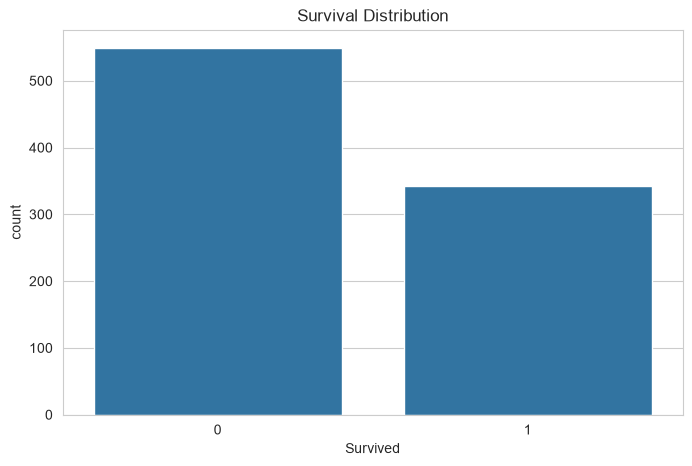

In [9]:
sns.countplot(
    x="Survived",
    data=df
)

plt.title("Survival Distribution")
plt.show()

### Observations

- More passengers did not survive than survived.
- The target variable shows a slight class imbalance.

# Numerical Feature Distributions

Analyze Age, Fare, SibSp, and Parch distributions.

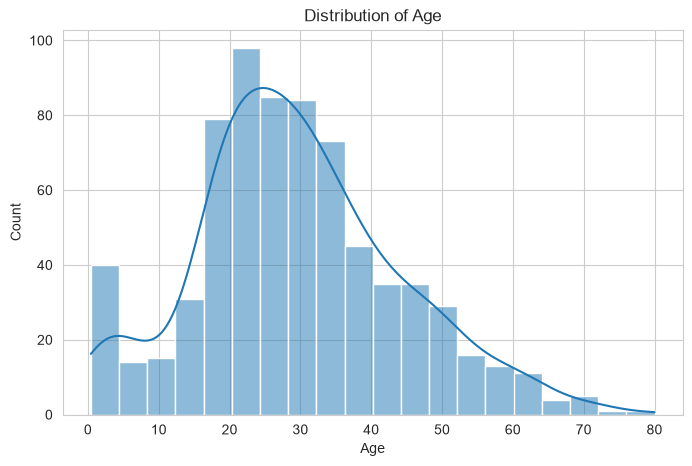

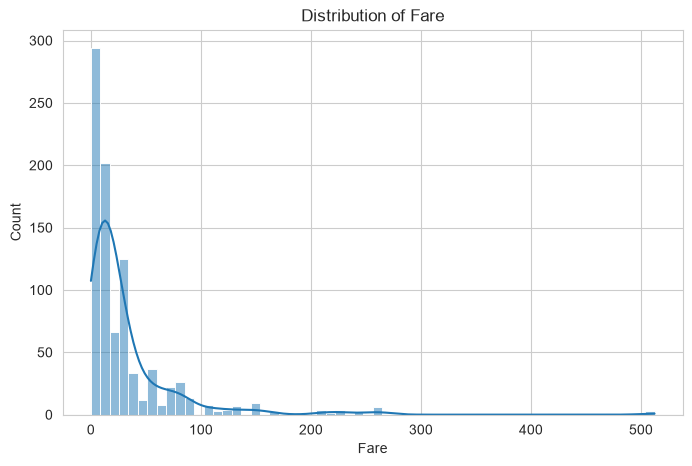

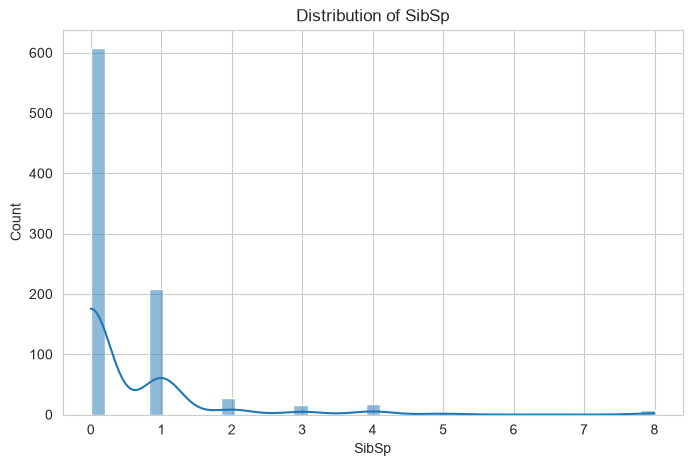

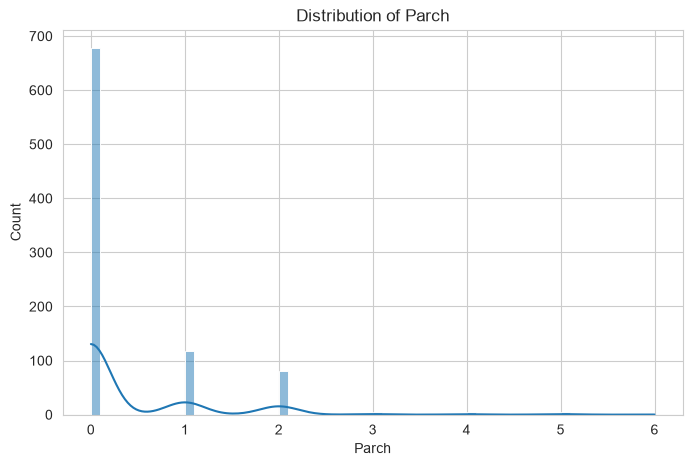

In [10]:
numerical_columns = [
    "Age",
    "Fare",
    "SibSp",
    "Parch"
]

for col in numerical_columns:

    plt.figure()

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.show()

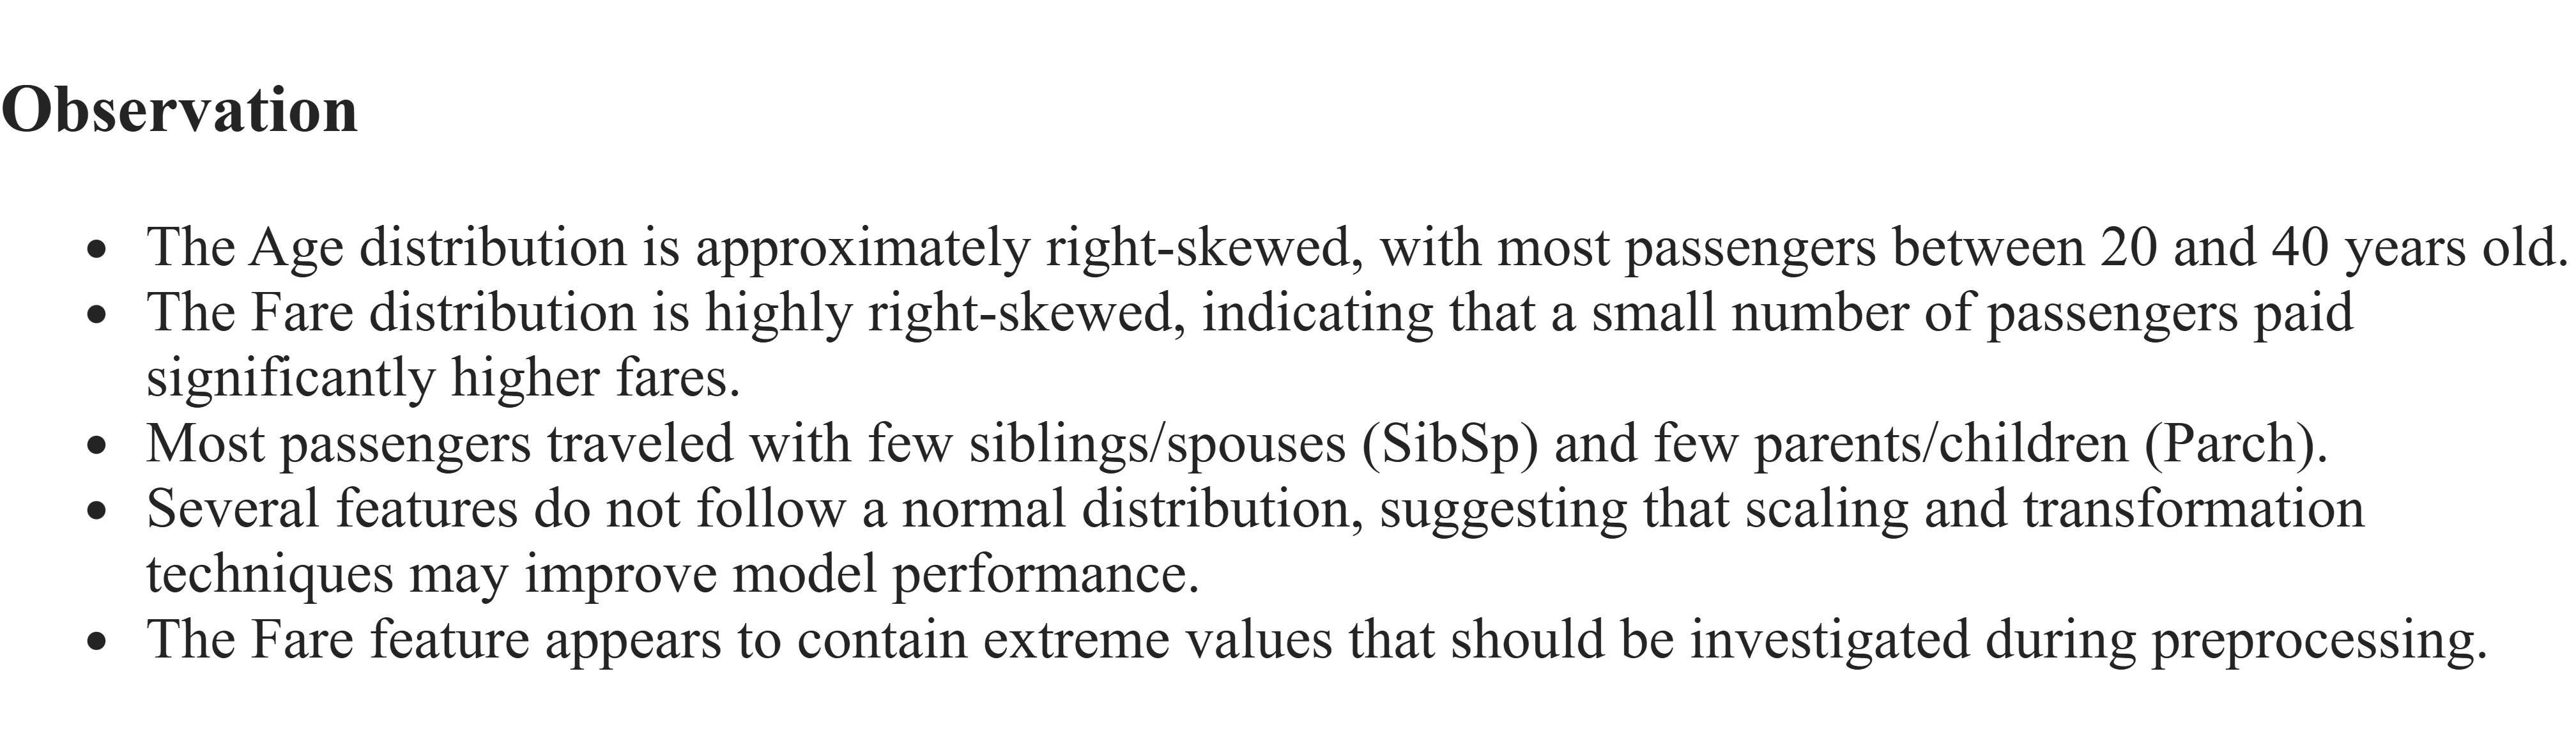


# Outlier Analysis

Identify potential outliers using boxplots.

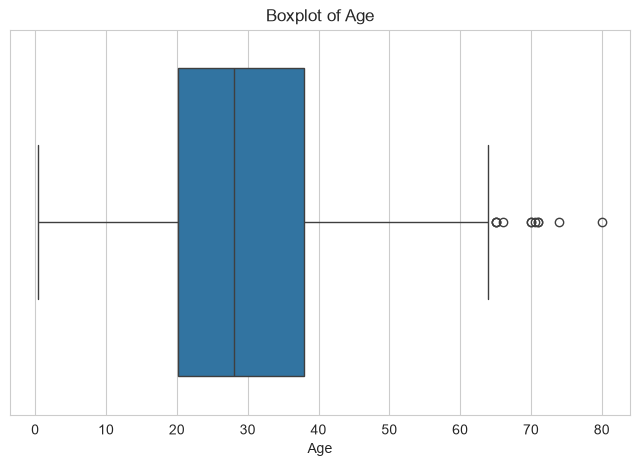

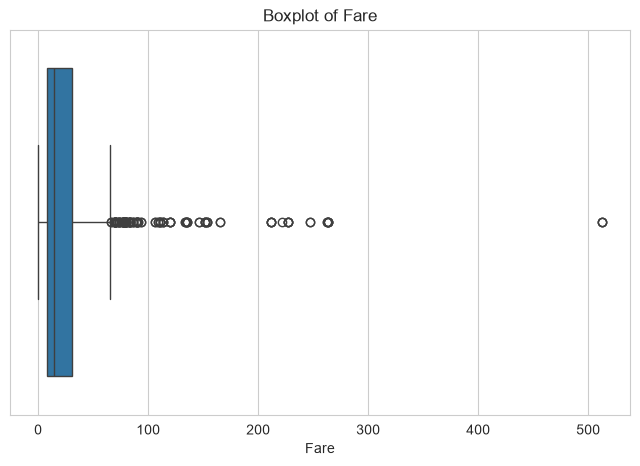

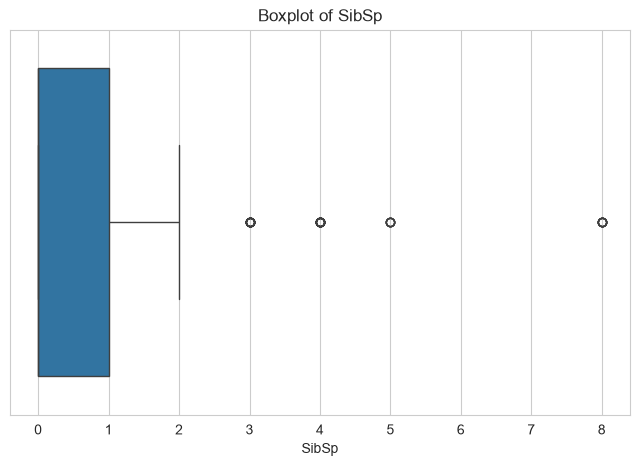

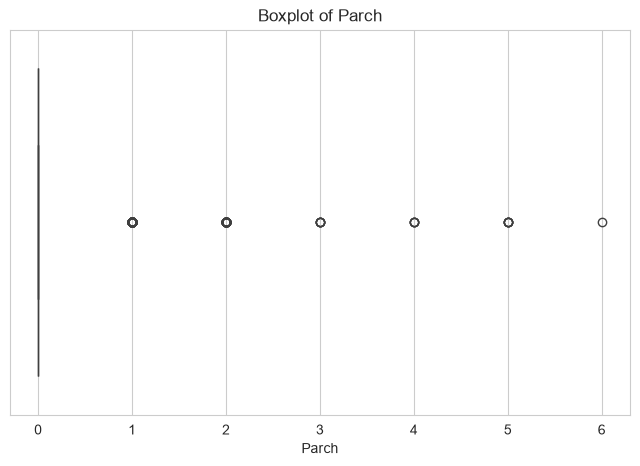

In [11]:
for col in numerical_columns:

    plt.figure()

    sns.boxplot(
        x=df[col]
    )

    plt.title(f"Boxplot of {col}")
    plt.show()

### Observations

- Fare contains significant outliers.
- Age contains a few extreme values.

# Categorical Feature Distributions

Analyze categorical variables such as Sex, Pclass, and Embarked.

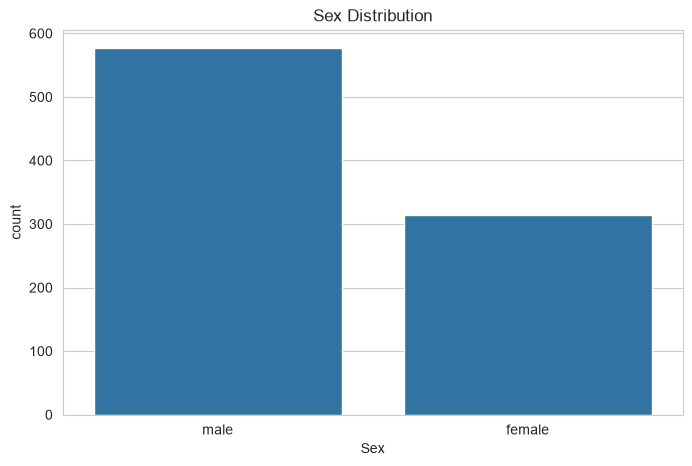

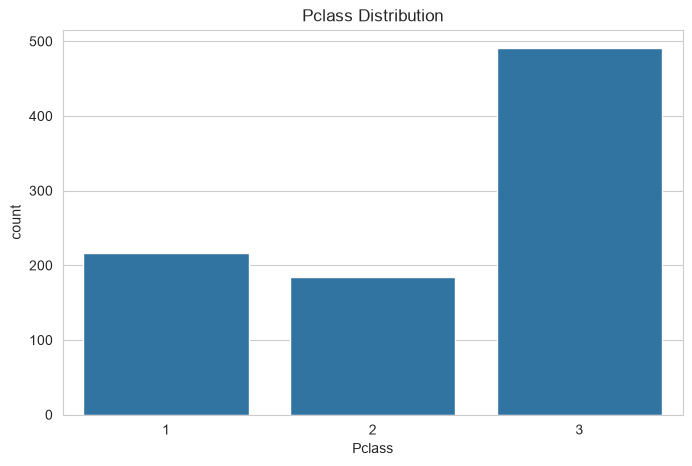

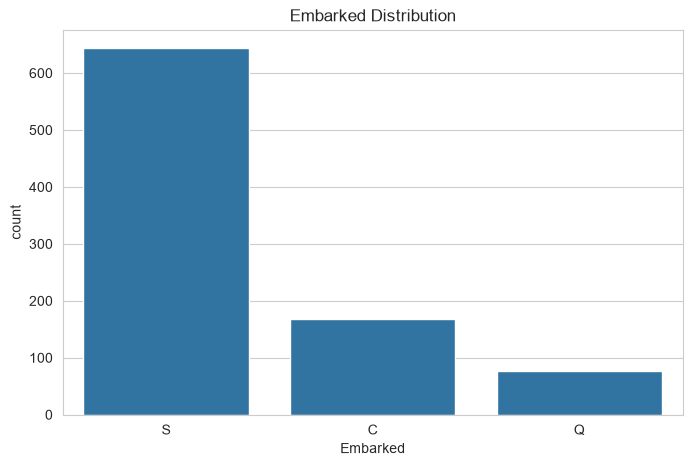

In [12]:
categorical_columns = [
    "Sex",
    "Pclass",
    "Embarked"
]

for col in categorical_columns:

    plt.figure()

    sns.countplot(
        x=col,
        data=df
    )

    plt.title(f"{col} Distribution")

    plt.show()

# Survival Analysis by Gender

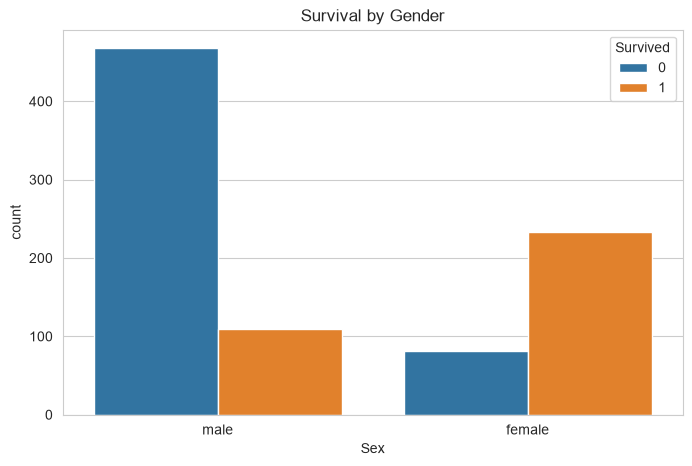

In [13]:
sns.countplot(
    x="Sex",
    hue="Survived",
    data=df
)

plt.title("Survival by Gender")
plt.show()

### Observations

- Female passengers had a significantly higher survival rate.
- Gender appears to be a strong predictor.

# Survival Analysis by Passenger Class

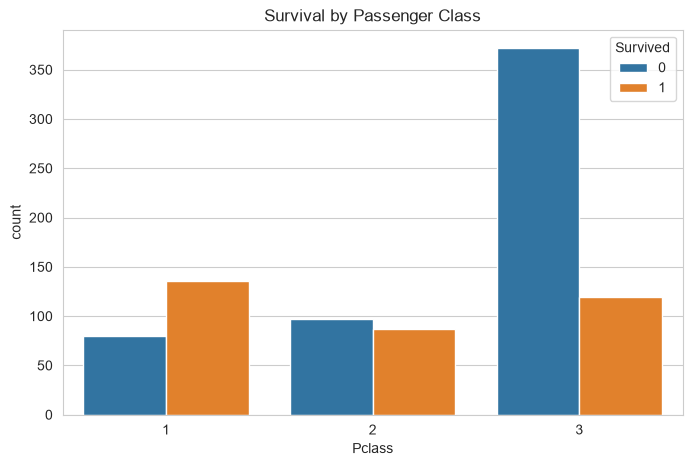

In [14]:
sns.countplot(
    x="Pclass",
    hue="Survived",
    data=df
)

plt.title("Survival by Passenger Class")
plt.show()

### Observations

- First-Class passengers had the highest survival rate.
- Passenger class appears strongly related to survival.

# Survival Analysis by Embarkation Port

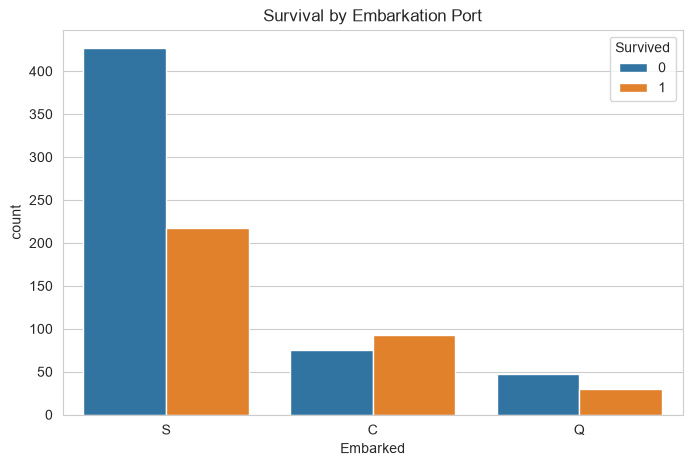

In [15]:
sns.countplot(
    x="Embarked",
    hue="Survived",
    data=df
)

plt.title("Survival by Embarkation Port")
plt.show()

# Feature Engineering

Create FamilySize and IsAlone features.

In [16]:
df["FamilySize"] = (
    df["SibSp"] +
    df["Parch"] +
    1
)

df["IsAlone"] = np.where(
    df["FamilySize"] == 1,
    1,
    0
)

df[["FamilySize", "IsAlone"]].head()

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1


**Family Size vs Survival**


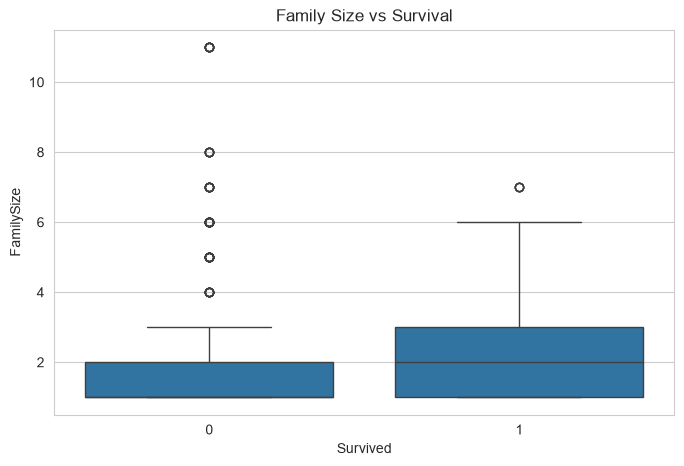

In [17]:
sns.boxplot(
    x="Survived",
    y="FamilySize",
    data=df
)

plt.title("Family Size vs Survival")
plt.show()

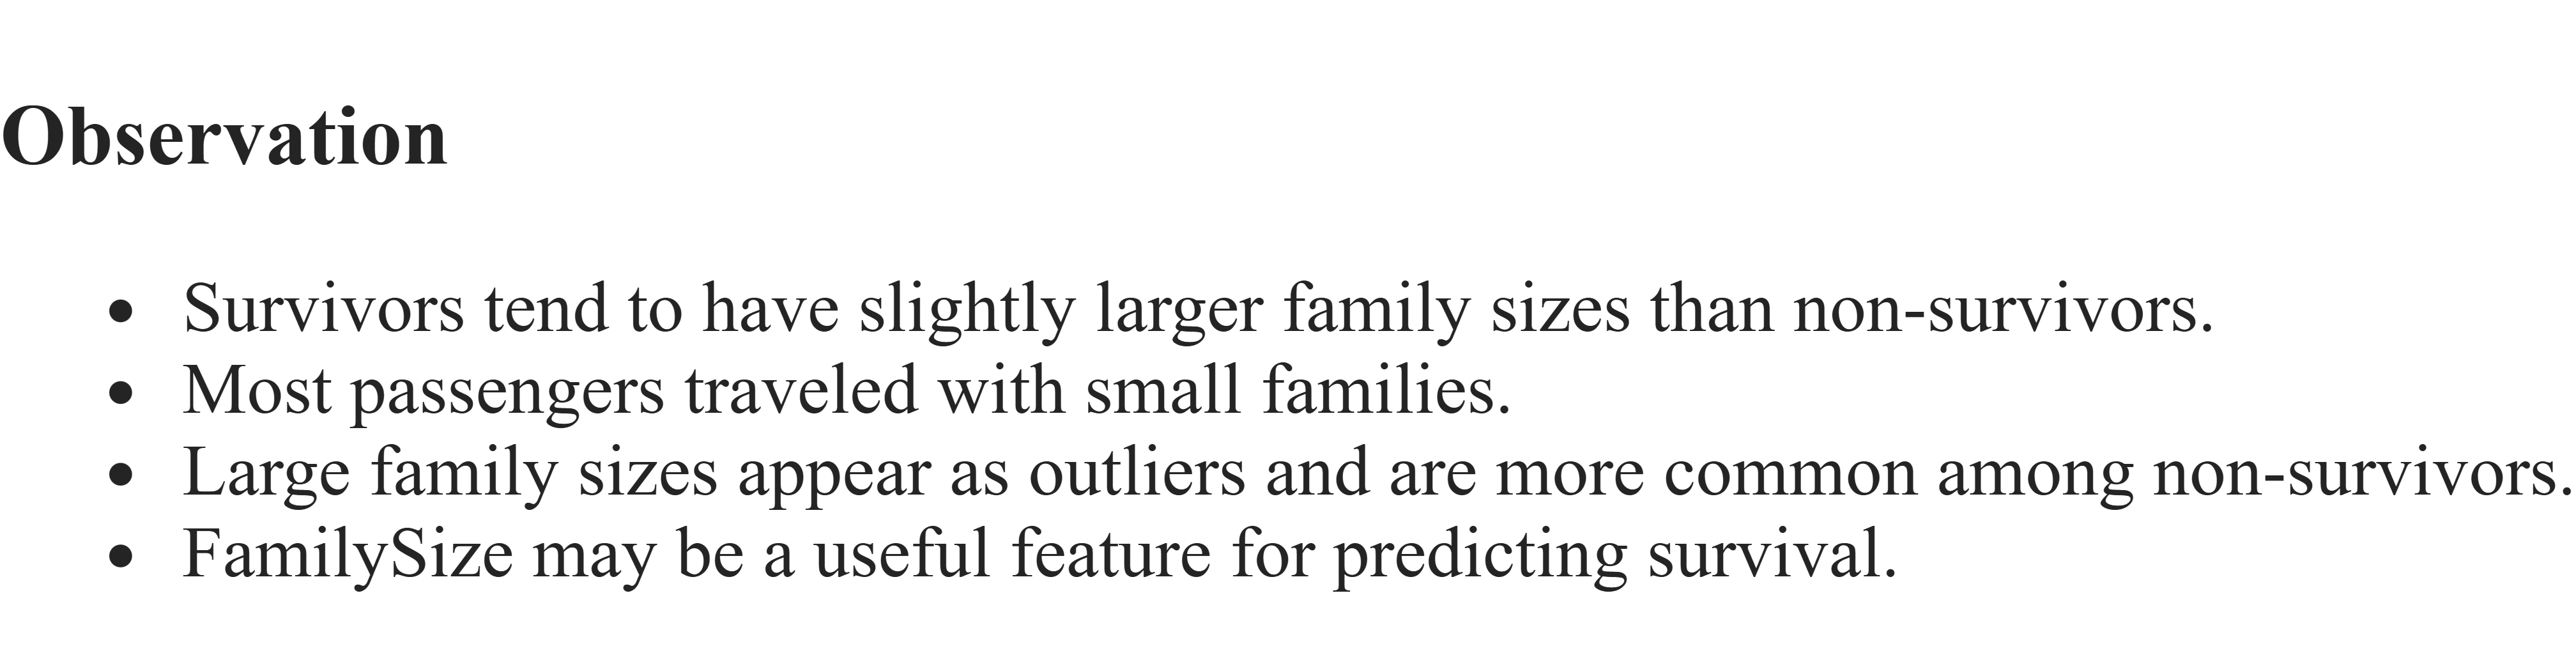

# Correlation Analysis

Identify relationships between numerical variables.

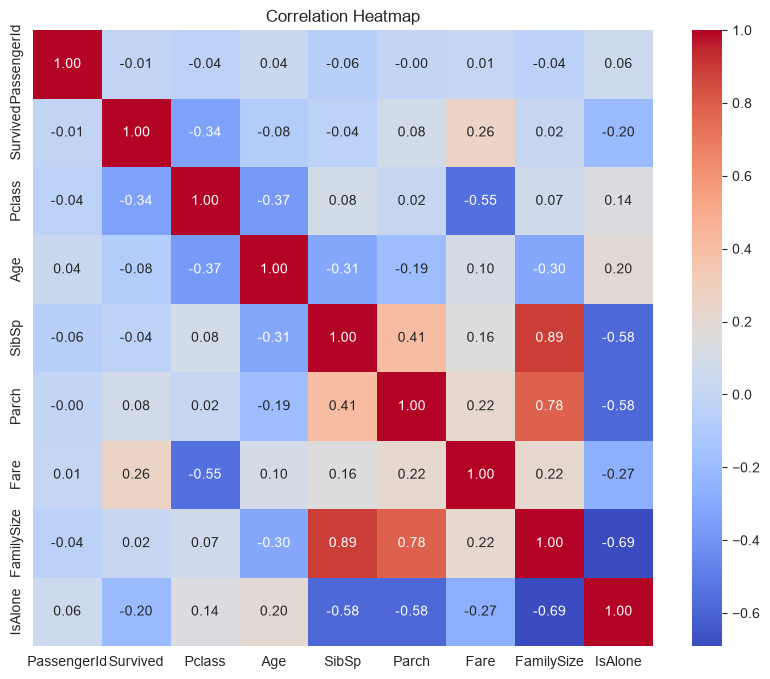

In [18]:
numeric_df = df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(10,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# EDA Findings Summary

In [19]:
eda_findings = pd.DataFrame({

    "Feature/Analysis": [
        "Dataset Shape",
        "Missing Values",
        "Cabin",
        "Age",
        "Embarked",
        "Sex",
        "Pclass",
        "Fare",
        "FamilySize"
    ],

    "Observation": [
        "891 rows and 12 columns",
        "Missing values present",
        "Large percentage missing",
        "Missing values detected",
        "Few missing values",
        "Strong survival predictor",
        "Strong survival predictor",
        "Contains outliers",
        "Useful engineered feature"
    ],

    "Recommended Action": [
        "Proceed with modeling",
        "Apply imputation",
        "Drop column",
        "Median imputation",
        "Mode imputation",
        "Retain feature",
        "Retain feature",
        "Scale feature",
        "Use in model training"
    ]
})

eda_findings.to_csv(
    "data\eda_findings.csv",
    index=False
)

print("\nEDA findings saved as 'eda_findings.csv'")


EDA findings saved as 'eda_findings.csv'


<>:41: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:41: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\gargi\AppData\Local\Temp\ipykernel_12552\2047113562.py:41: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  "data\eda_findings.csv",


# Final EDA Conclusion

Key findings from the analysis:

- Cabin contains excessive missing values and should be removed.
- Age requires median imputation.
- Embarked requires mode imputation.
- Female passengers had significantly higher survival rates.
- First-Class passengers had better survival outcomes.
- Fare contains outliers and will require scaling.
- FamilySize and IsAlone are useful engineered features.

### Recommended Features

- Sex
- Pclass
- Age
- Fare
- Embarked
- FamilySize
- IsAlone

### Features To Remove

- PassengerId
- Ticket
- Cabin